# Sensitivity Analysis

In this notebook, I compare the sensitivity of three approaches to changes in volatility:

- Crank-Nicolson finite difference method
- PINN with modified loss
- PIKAN

The main sensitivity experiment varies volatility $\sigma$, while keeping the other parameters fixed. For each volatility value, each method is evaluated against the analytical Black-Scholes solution using the same stock-price and time-to-maturity grid.

The aim is to assess how robust each method is as the option-pricing problem becomes more or less volatile.

The $\sigma$ values I will use are $\sigma \in [0.1, 0.2, 0.3, 0.4]$.

In [6]:
import sys
sys.path.append("..")

import time
import gc
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.analytical import call_price
from src.metrics import error_summary
from src.training_points import generate_training_points
from src.losses import black_scholes_pde_loss
from src.evaluation import evaluate_model_on_grid

from src.pinn import BlackScholesPINN
from src.pikan import BlackScholesPIKAN
from src.crank_nicolson import Crank_Nicolson_Solver

torch.set_num_threads(1)

torch.manual_seed(42)
np.random.seed(42)

In [ ]:
# Defining parameters.

K = 100
T = 1.0
r = 0.05
S0 = 100
S_max = 200

sigma_values = [0.1, 0.2, 0.3, 0.4]

S_eval = np.linspace(0, S_max, 100)
tau_eval = np.array([T])  # final pricing curve only

In [20]:
# Defining an analytical reference.

def analytical_prices_for_sigma(sigma):
    tau_curve = np.full_like(S_eval, T)

    return call_price(
        S_eval,
        tau_curve,
        K=K,
        r=r,
        sigma=sigma
    )

In [21]:
def run_crank_nicolson(sigma, M=100, N=100):
    start_time = time.perf_counter()

    solver = Crank_Nicolson_Solver(
        S0=S0,
        K=K,
        T=T,
        r=r,
        sigma=sigma,
        S_max=S_max,
        M=M,
        N=N
    )

    result = solver.solve()

    price_cn = result[0]
    S_cn = result[1]
    V_cn = result[2]

    runtime = time.perf_counter() - start_time

    V_interp = np.interp(S_eval, S_cn, V_cn)

    return V_interp, runtime

In [15]:
# Defining a function that trains my PINN for varying volatility.

def train_pinn_modified_loss(sigma):
    torch.manual_seed(42)
    np.random.seed(42)

    model_mod_loss = BlackScholesPINN(
        layers=[2, 32, 32, 32, 1],
        S_max=S_max,
        T=T,
        price_scale=K
    )

    optimizer_mod_loss = torch.optim.Adam(model_mod_loss.parameters(), lr=1e-3)

    loss_history_mod_loss = []

    epochs = 5000
    N_f = 500
    N_ic = 200
    N_bc = 200

    start_time = time.perf_counter()

    for epoch in range(epochs):
        training_data = generate_training_points(
            N_f=N_f,
            N_ic=N_ic,
            N_bc=N_bc,
            S_max=S_max,
            T=T,
            K=K,
            r=r
        )

        optimizer_mod_loss.zero_grad(set_to_none=True)

        total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
            model_mod_loss,
            training_data,
            r=r,
            sigma=sigma,
            K=K,
            weight_ic=5.0
        )

        total_loss.backward()
        optimizer_mod_loss.step()

        loss_history_mod_loss.append(total_loss.detach().item())

        if epoch % 100 == 0:
            gc.collect()

        if epoch % 500 == 0:
            print(
                f"PINN | sigma={sigma} | Epoch {epoch}: "
                f"Total={total_loss.detach().item():.6e}, "
                f"PDE={loss_pde.detach().item():.6e}, "
                f"IC={loss_ic.detach().item():.6e}, "
                f"LB={loss_lb.detach().item():.6e}, "
                f"UB={loss_ub.detach().item():.6e}"
            )

    runtime = time.perf_counter() - start_time

    return model_mod_loss, runtime, loss_history_mod_loss

In [16]:
# Defining a function that trains my PIKAN for varying volatility.

def train_pikan(sigma):
    torch.manual_seed(42)
    np.random.seed(42)

    model_pikan = BlackScholesPIKAN(
        layers=[2, 16, 16, 1],
        grid=5,
        degree=3,
        S_max=S_max,
        T=T,
        seed=42
    )

    model_pikan.train()

    optimizer = torch.optim.Adam(model_pikan.parameters(), lr=1e-3)

    loss_history = []

    epochs = 3000
    N_f = 300
    N_ic = 150
    N_bc = 150

    start_time = time.perf_counter()

    for epoch in range(epochs):
        training_data = generate_training_points(
            N_f=N_f,
            N_ic=N_ic,
            N_bc=N_bc,
            S_max=S_max,
            T=T,
            K=K,
            r=r
        )

        optimizer.zero_grad(set_to_none=True)

        total_loss, loss_pde, loss_ic, loss_lb, loss_ub = black_scholes_pde_loss(
            model_pikan,
            training_data,
            r=r,
            sigma=sigma,
            K=K
        )

        total_loss.backward()
        optimizer.step()

        loss_history.append(total_loss.detach().item())

        if epoch % 100 == 0:
            gc.collect()

        if epoch % 500 == 0:
            print(
                f"PIKAN | sigma={sigma} | Epoch {epoch}: "
                f"Total={total_loss.detach().item():.6e}, "
                f"PDE={loss_pde.detach().item():.6e}, "
                f"IC={loss_ic.detach().item():.6e}, "
                f"LB={loss_lb.detach().item():.6e}, "
                f"UB={loss_ub.detach().item():.6e}"
            )

    runtime = time.perf_counter() - start_time

    return model_pikan, runtime, loss_history

In [23]:
# Running sensitivity analysis.

sensitivity_rows = []

for sigma in sigma_values:
    print(f"\nRunning sigma = {sigma}")

    tau_curve = np.full_like(S_eval, T)

    V_exact = analytical_prices_for_sigma(sigma)

    # Crank-Nicolson
    V_cn, cn_runtime = run_crank_nicolson(sigma)
    cn_metrics = error_summary(V_cn, V_exact)

    sensitivity_rows.append({
        "Method": "Crank-Nicolson",
        "sigma": sigma,
        "Runtime": cn_runtime,
        **cn_metrics
    })

    # PINN + Modified Loss
    pinn_model, pinn_runtime, pinn_loss = train_pinn_modified_loss(sigma)

    V_pinn, _ = evaluate_model_on_grid(
        pinn_model,
        S_eval,
        tau_curve,
        K,
        r,
        sigma
    )

    V_pinn = V_pinn.reshape(-1)

    pinn_metrics = error_summary(V_pinn, V_exact)

    sensitivity_rows.append({
        "Method": "PINN + Modified Loss",
        "sigma": sigma,
        "Runtime": pinn_runtime,
        **pinn_metrics
    })

    # PIKAN
    pikan_model, pikan_runtime, pikan_loss = train_pikan(sigma)

    V_pikan, _ = evaluate_model_on_grid(
        pikan_model,
        S_eval,
        tau_curve,
        K,
        r,
        sigma
    )

    V_pikan = V_pikan.reshape(-1)

    pikan_metrics = error_summary(V_pikan, V_exact)

    sensitivity_rows.append({
        "Method": "PIKAN",
        "sigma": sigma,
        "Runtime": pikan_runtime,
        **pikan_metrics
    })


# A table of results for the sensitivity analysis.
sensitivity_table = pd.DataFrame(sensitivity_rows)
sensitivity_table


Running sigma = 0.1
PINN | sigma=0.1 | Epoch 0: Total=2.519665e+00, PDE=8.999108e-05, IC=2.197793e-01, LB=1.568664e-02, UB=1.404992e+00
PINN | sigma=0.1 | Epoch 500: Total=8.151983e-03, PDE=1.712381e-03, IC=1.220498e-03, LB=1.467686e-04, UB=1.903411e-04
PINN | sigma=0.1 | Epoch 1000: Total=2.188580e-03, PDE=3.369559e-04, IC=3.416819e-04, LB=7.700913e-05, UB=6.620533e-05
PINN | sigma=0.1 | Epoch 1500: Total=1.786579e-03, PDE=2.435747e-04, IC=2.903747e-04, LB=8.234439e-05, UB=8.785868e-06
PINN | sigma=0.1 | Epoch 2000: Total=9.537857e-04, PDE=1.139053e-04, IC=1.533693e-04, LB=6.541327e-05, UB=7.620725e-06
PINN | sigma=0.1 | Epoch 2500: Total=4.537397e-04, PDE=6.358277e-05, IC=7.343264e-05, LB=8.218205e-06, UB=1.477562e-05
PINN | sigma=0.1 | Epoch 3000: Total=2.755154e-04, PDE=6.979946e-05, IC=3.884927e-05, LB=2.827598e-06, UB=8.641947e-06
PINN | sigma=0.1 | Epoch 3500: Total=2.395555e-04, PDE=7.517687e-05, IC=3.143957e-05, LB=3.429379e-06, UB=3.751426e-06
PINN | sigma=0.1 | Epoch 4000: 

,Method,sigma,Runtime,MSE,RMSE,MAE,Max Abs Error,Relative L2 Error
0,Crank-Nicolson,0.1,0.012112,0.000013,0.003605,0.001399,0.014840,0.000081
1,PINN + Modified Loss,0.1,39.917142,0.150267,0.387643,0.304292,0.913229,0.008755
2,PIKAN,0.1,267.012534,0.000319,0.017856,0.012738,0.089521,0.000403
3,Crank-Nicolson,0.2,0.006516,0.000004,0.001936,0.000985,0.006102,0.000044
4,PINN + Modified Loss,0.2,27.769635,0.144442,0.380055,0.282335,0.764966,0.008550
5,PIKAN,0.2,403.824237,0.000530,0.023014,0.015272,0.125084,0.000518
6,Crank-Nicolson,0.3,0.013058,0.000406,0.020154,0.008929,0.088164,0.000448
7,PINN + Modified Loss,0.3,80.932007,0.181055,0.425505,0.347209,0.849413,0.009452
8,PIKAN,0.3,639.840202,0.002573,0.050726,0.030167,0.250927,0.001127
9,Crank-Nicolson,0.4,0.005069,0.033453,0.182902,0.088071,0.669549,0.003962


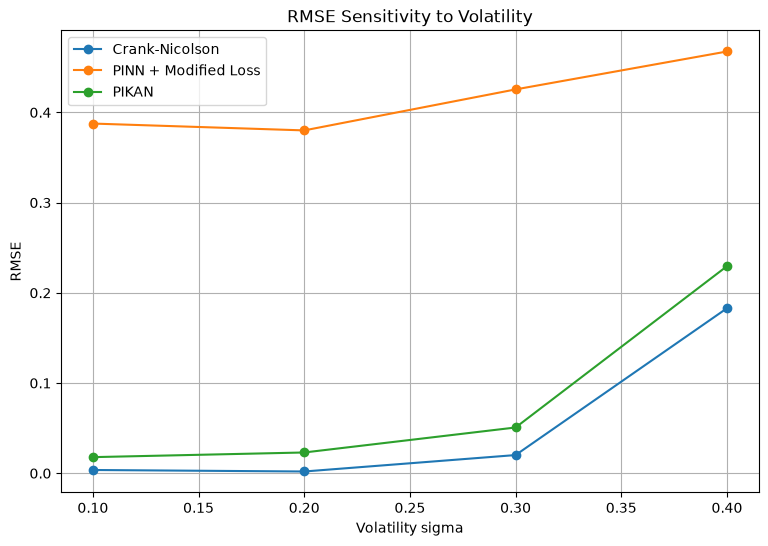

In [24]:
# Plotting RMSE sensitivity.

sensitivity_table.columns

plt.figure(figsize=(9, 6))

for method in sensitivity_table["Method"].unique():
    subset = sensitivity_table[sensitivity_table["Method"] == method]
    plt.plot(subset["sigma"], subset["RMSE"], marker="o", label=method)

plt.xlabel("Volatility sigma")
plt.ylabel("RMSE")
plt.title("RMSE Sensitivity to Volatility")
plt.grid()
plt.legend()
plt.show()

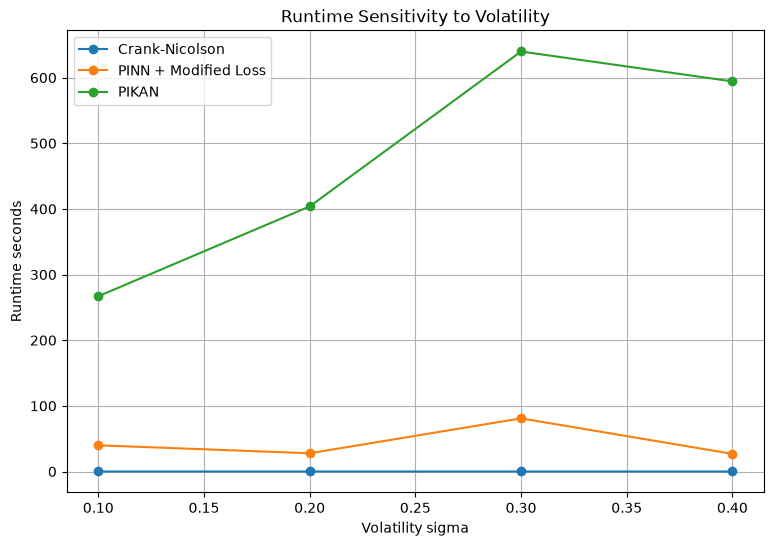

In [25]:
# Plotting runtime sensitivity.

plt.figure(figsize=(9, 6))

for method in sensitivity_table["Method"].unique():
    subset = sensitivity_table[sensitivity_table["Method"] == method]
    plt.plot(subset["sigma"], subset["Runtime"], marker="o", label=method)

plt.xlabel("Volatility sigma")
plt.ylabel("Runtime seconds")
plt.title("Runtime Sensitivity to Volatility")
plt.grid(True)
plt.legend()
plt.show()

The runtime plot should be interpreted carefully because the neural model runtimes include full retraining for each volatility value, whereas Crank-Nicolson only requires solving the finite-difference system.

## Sensitivity Analysis Results

The sensitivity analysis compares the behaviour of Crank-Nicolson, the PINN with modified loss, and the PIKAN model as volatility $\sigma$ increases. For each volatility value, the neural models were retrained and all methods were compared against the analytical Black-Scholes solution.

The Crank-Nicolson method gives the strongest overall performance. It has the lowest RMSE, MAE, maximum absolute error, and relative L2 error for each volatility value, while also being by far the fastest method. This is expected because Crank-Nicolson is a direct finite-difference method designed specifically for this type of parabolic PDE.

The PIKAN model performs substantially better than the PINN with modified loss in terms of accuracy. Across all volatility values, the PIKAN has much lower RMSE and relative L2 error than the PINN. However, this comes at a significant computational cost, with training times much higher than both Crank-Nicolson and the PINN.

The PINN with modified loss is the least accurate of the three methods. Its error remains relatively stable as volatility increases, but it does not achieve the same accuracy as the PIKAN or Crank-Nicolson method. This suggests that, for this setup, the modified loss improves training stability but is not enough to make the PINN competitive with the other two methods.

As volatility increases, both neural methods show a general increase in error, especially at $\sigma = 0.4$. This is reasonable because higher volatility changes the shape of the option price curve and makes the learning problem more difficult. Crank-Nicolson also shows a noticeable increase in RMSE at $\sigma = 0.4$, although its relative L2 error remains small.

Overall, the results show a clear trade-off. Crank-Nicolson is the most accurate and efficient method for the one-dimensional Black-Scholes equation. PIKAN gives better accuracy than the PINN but is much more expensive to train. The PINN is faster than PIKAN but less accurate across all tested volatility values.